# Detecção de Fraudes em Cartão de Crédito
### Isolation Forest × Local Outlier Factor

Projeto Integrador VI — PUC-Campinas

## Sumário

1. [Introdução](#1)
2. [Pacotes e configurações](#2)
3. [Leitura e limpeza dos dados](#3)
4. [Verificação dos dados](#4)
5. [Exploração dos dados](#5)
6. [Divisão dos dados](#6)
7. [Pré-processamento](#7)
8. [Seleção de features](#8)
9. [Modelos](#9)
10. [Limite de decisão](#10)
11. [Avaliação final](#11)
12. [Salvando o modelo](#12)
13. [Conclusões](#13)
14. [Limitações](#14)
15. [Referências](#15)

# <a id="1"></a>1. Introdução

O dataset reúne transações feitas com cartões de crédito europeus em **setembro de 2013**, ao longo de **dois dias**. São **284.807 transações**, das quais só **492 são fraudes (0,17%)**.

- `V1` a `V28`: colunas anônimas, já transformadas por PCA pelo banco, por privacidade.
- `Time`: segundos desde a primeira transação.
- `Amount`: valor da transação, em euros.
- `Class`: 1 para fraude, 0 para normal.

**Objetivo:** identificar fraudes com **detecção de anomalias**. Os dois modelos usados aprendem só com transações normais o que é "comportamento normal" e marcam o que foge disso. Não precisam de exemplos de fraude para treinar.

**O caminho deste notebook:**

1. Limpar e entender os dados.
2. Dividir em treino, validação e apresentação, antes de qualquer outra coisa.
3. Escolher as colunas mais úteis com **informação mútua**, calculada só no treino.
4. Testar **Isolation Forest** e **LOF** com vários subconjuntos de colunas e parâmetros, na validação.
5. Avaliar os finalistas uma única vez no conjunto de apresentação.
6. Salvar o modelo escolhido para a API e o dashboard.

# <a id="2"></a>2. Pacotes e configurações

Todos os imports ficam aqui, junto com as configurações usadas no notebook inteiro. O `RANDOM_STATE` fixo garante que qualquer pessoa do grupo obtenha exatamente os mesmos resultados.

In [1]:
import time
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.feature_selection import mutual_info_classif
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             jaccard_score, average_precision_score, roc_auc_score,
                             roc_curve, precision_recall_curve, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore", message="X does not have valid feature names")

RANDOM_STATE = 42

PASTA_DADOS = Path("../data")
PASTA_RESULTADOS = Path("../resultados")
PASTA_MODELOS = Path("../modelos")
PASTA_RESULTADOS.mkdir(exist_ok=True)
PASTA_MODELOS.mkdir(exist_ok=True)

CORES = {"Normal": "#8C96A3", "Fraude": "#C2410C",
         "Isolation Forest": "#1D4ED8", "LOF": "#0F766E"}

sns.set_style("whitegrid")

# <a id="3"></a>3. Leitura e limpeza dos dados

O dataset tem transações repetidas: linhas idênticas em todas as colunas, inclusive no horário. Elas são removidas logo no início por dois motivos:

- **Vazamento:** uma cópia poderia cair no treino e outra na avaliação, e o modelo seria avaliado numa transação que já viu.
- **LOF:** ele mede distâncias entre transações, e linhas iguais (distância zero) atrapalham o cálculo.

In [2]:
df = pd.read_csv(PASTA_DADOS / "creditcard.csv")
print(f"Lido: {len(df):,} transações | {df['Class'].sum()} fraudes")

duplicadas = df.duplicated()
print(f"Linhas duplicadas: {duplicadas.sum():,} | fraudes entre elas: {df.loc[duplicadas, 'Class'].sum()}")

df = df.drop_duplicates().reset_index(drop=True)
print(f"Depois da limpeza: {len(df):,} transações | {df['Class'].sum()} fraudes")

Lido: 284,807 transações | 492 fraudes
Linhas duplicadas: 1,081 | fraudes entre elas: 19
Depois da limpeza: 283,726 transações | 473 fraudes


# <a id="4"></a>4. Verificação dos dados

Primeiro, um olhar geral: tamanho, valores nulos e média e desvio de cada coluna.

In [3]:
print("Linhas e colunas:", df.shape)
print("Valores nulos:", df.isnull().sum().sum())
display(df.head())
df.describe().T[["mean", "std", "min", "max"]].round(3)

Linhas e colunas: (283726, 31)
Valores nulos: 0


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


,mean,std,min,max
Time,94811.078,47481.048,0.000,172792.000
V1,0.006,1.948,-56.408,2.455
V2,-0.004,1.647,-72.716,22.058
V3,0.002,1.509,-48.326,9.383
V4,-0.003,1.414,-5.683,16.875
V5,0.002,1.377,-113.743,34.802
V6,-0.001,1.332,-26.161,73.302
V7,0.002,1.228,-43.557,120.589
V8,-0.001,1.179,-73.217,20.007
V9,-0.002,1.095,-13.434,15.595


**O que observar:** `V1` a `V28` têm média perto de zero e desvio caindo de `V1` até `V28`. É a assinatura do PCA, que ordena as componentes da que mais varia para a que menos varia. `Time` e `Amount` estão em outra escala, porque não passaram pelo PCA. Por isso precisam de tratamento no pré-processamento.

## 4.1 Desbalanceamento

Esse é o ponto que define todo o resto do projeto.

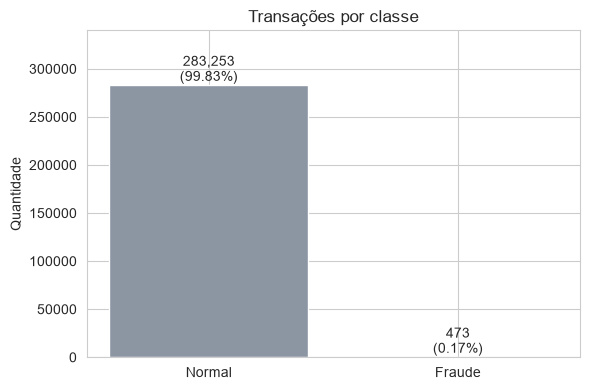

In [4]:
contagem = df["Class"].value_counts().sort_index()
rotulos = ["Normal", "Fraude"]

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(rotulos, contagem.values, color=[CORES["Normal"], CORES["Fraude"]])
for i, valor in enumerate(contagem.values):
    ax.text(i, valor, f"{valor:,}\n({valor / len(df):.2%})", ha="center", va="bottom")
ax.set_title("Transações por classe")
ax.set_ylabel("Quantidade")
ax.set_ylim(0, contagem.max() * 1.2)
plt.tight_layout()
plt.savefig(PASTA_RESULTADOS / "desbalanceamento.png", dpi=150)
plt.show()

Com cerca de 0,17% de fraude, um modelo que diz "normal" para tudo acerta 99,83% das vezes e não pega nenhuma fraude. Por isso **a acurácia não serve para escolher modelo** aqui. As métricas usadas olham para as fraudes:

- **Precision:** das transações marcadas como fraude, quantas eram fraude.
- **Recall:** das fraudes reais, quantas o modelo pegou.
- **F1:** equilíbrio entre as duas.
- **AUPRC:** qualidade da pontuação em todos os limites de corte. Um modelo aleatório tira cerca de 0,0017, a própria proporção de fraude. É a métrica principal de escolha.

# <a id="5"></a>5. Exploração dos dados

Antes de modelar, vale entender como as fraudes se comportam no que é legível: horário, valor e a distribuição das colunas.

## 5.1 Transações ao longo do dia

`Time` está em segundos desde a primeira transação. Convertendo para hora do dia, dá para comparar o volume normal com a proporção de fraude. Como a contagem começa na primeira transação, e não à meia-noite, a "hora 0" é aproximada.

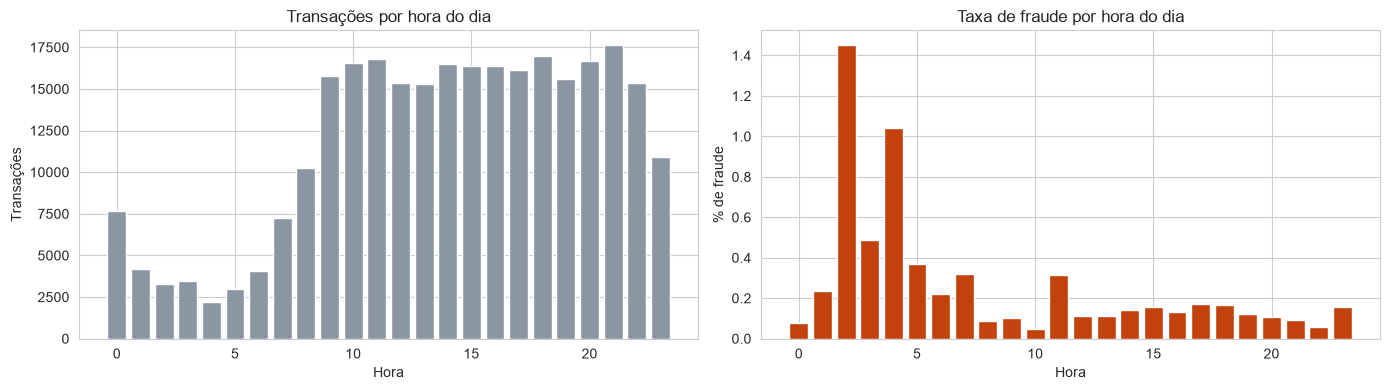

,transacoes,fraudes,taxa_fraude_%
Hora,,,
2,3308,48,1.451
4,2204,23,1.044
3,3487,17,0.488
5,2988,11,0.368
7,7233,23,0.318


In [5]:
explo = df.copy()
explo["Hora"] = (explo["Time"] // 3600 % 24).astype(int)

por_hora = explo.groupby("Hora")["Class"].agg(transacoes="count", fraudes="sum")
por_hora["taxa_fraude_%"] = por_hora["fraudes"] / por_hora["transacoes"] * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
ax1.bar(por_hora.index, por_hora["transacoes"], color=CORES["Normal"])
ax1.set_title("Transações por hora do dia")
ax1.set_xlabel("Hora")
ax1.set_ylabel("Transações")
ax2.bar(por_hora.index, por_hora["taxa_fraude_%"], color=CORES["Fraude"])
ax2.set_title("Taxa de fraude por hora do dia")
ax2.set_xlabel("Hora")
ax2.set_ylabel("% de fraude")
plt.tight_layout()
plt.savefig(PASTA_RESULTADOS / "fraude_por_hora.png", dpi=150)
plt.show()

por_hora.sort_values("taxa_fraude_%", ascending=False).head(5).round(3)

**O que observar:** nas horas de pouco movimento (o vale do gráfico da esquerda), a proporção de fraude costuma subir. As fraudes não seguem o ritmo do dia como as compras normais.

## 5.2 Valor das transações

Os boxplots comparam o valor (`Amount`) de fraudes e de transações normais. O da direita esconde os valores extremos, para dar para ver o miolo da distribuição.

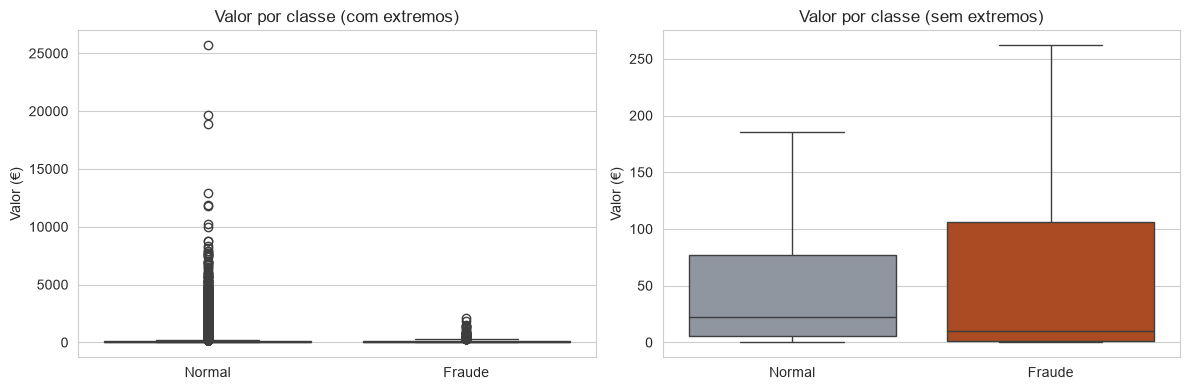

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
Normal,283253.0,88.41,250.38,0.0,5.67,22.00,77.46,25691.16
Fraude,473.0,123.87,260.21,0.0,1.00,9.82,105.89,2125.87


In [6]:
paleta = {0: CORES["Normal"], 1: CORES["Fraude"]}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df, x="Class", y="Amount", hue="Class", palette=paleta,
            showfliers=True, legend=False, ax=ax1)
sns.boxplot(data=df, x="Class", y="Amount", hue="Class", palette=paleta,
            showfliers=False, legend=False, ax=ax2)
ax1.set_title("Valor por classe (com extremos)")
ax2.set_title("Valor por classe (sem extremos)")
for ax in (ax1, ax2):
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Normal", "Fraude"])
    ax.set_xlabel("")
    ax.set_ylabel("Valor (€)")
plt.tight_layout()
plt.savefig(PASTA_RESULTADOS / "valor_por_classe.png", dpi=150)
plt.show()

df.groupby("Class")["Amount"].describe().rename(index={0: "Normal", 1: "Fraude"}).round(2)

**O que observar:** compare a mediana (50%) e a média das duas classes. A fraude típica tende a ser pequena, mas algumas muito altas puxam a média para cima. Valor, sozinho, não separa bem as classes.

## 5.3 Correlação entre as colunas

O mapa mostra a correlação de Pearson entre todas as colunas. Vermelho é correlação positiva, azul é negativa e branco é ausência de correlação.

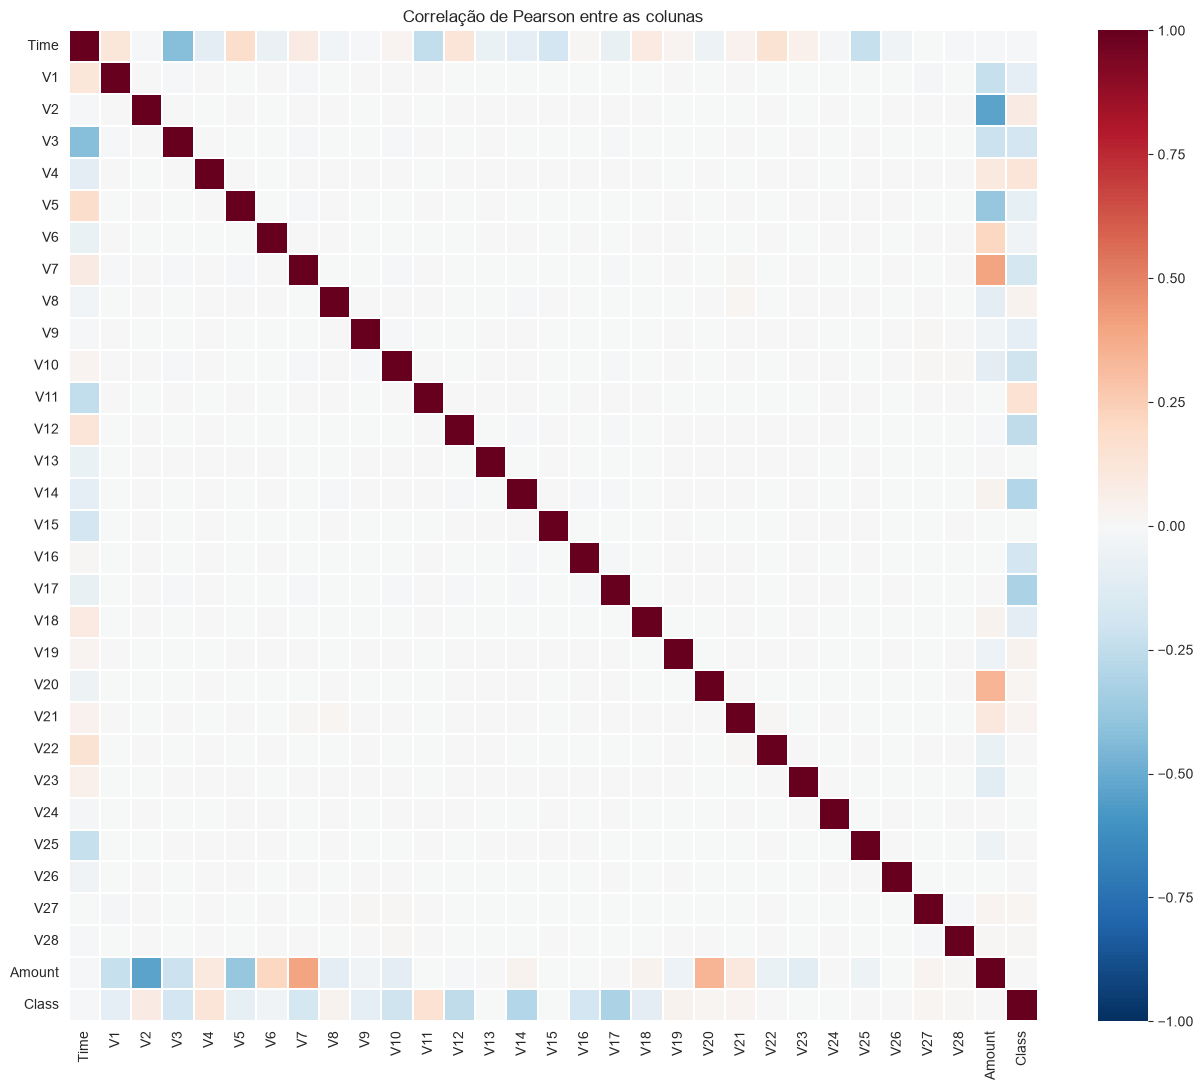

In [7]:
plt.figure(figsize=(13, 11))
sns.heatmap(df.corr(), cmap="RdBu_r", center=0, vmin=-1, vmax=1, linewidths=0.1)
plt.title("Correlação de Pearson entre as colunas")
plt.tight_layout()
plt.savefig(PASTA_RESULTADOS / "correlacao.png", dpi=150)
plt.show()

**O que observar:**

- Entre `V1` e `V28`, quase tudo é branco. O PCA gera colunas independentes entre si, então **não há colunas redundantes para remover**.
- `Time` e `Amount` têm alguma correlação com certas colunas `V`, porque ficaram fora do PCA.
- Na linha da `Class`, as cores são fracas. Com fraude tão rara, a correlação com a classe fica achatada, e por isso ela não serve como critério de corte com valor fixo.

## 5.4 Distribuição de cada coluna por classe

Para cada coluna, as duas curvas mostram como os valores se distribuem nas transações normais (cinza) e nas fraudes (laranja). Para o gráfico ficar leve, foram usadas 20 mil transações normais sorteadas e todas as fraudes.

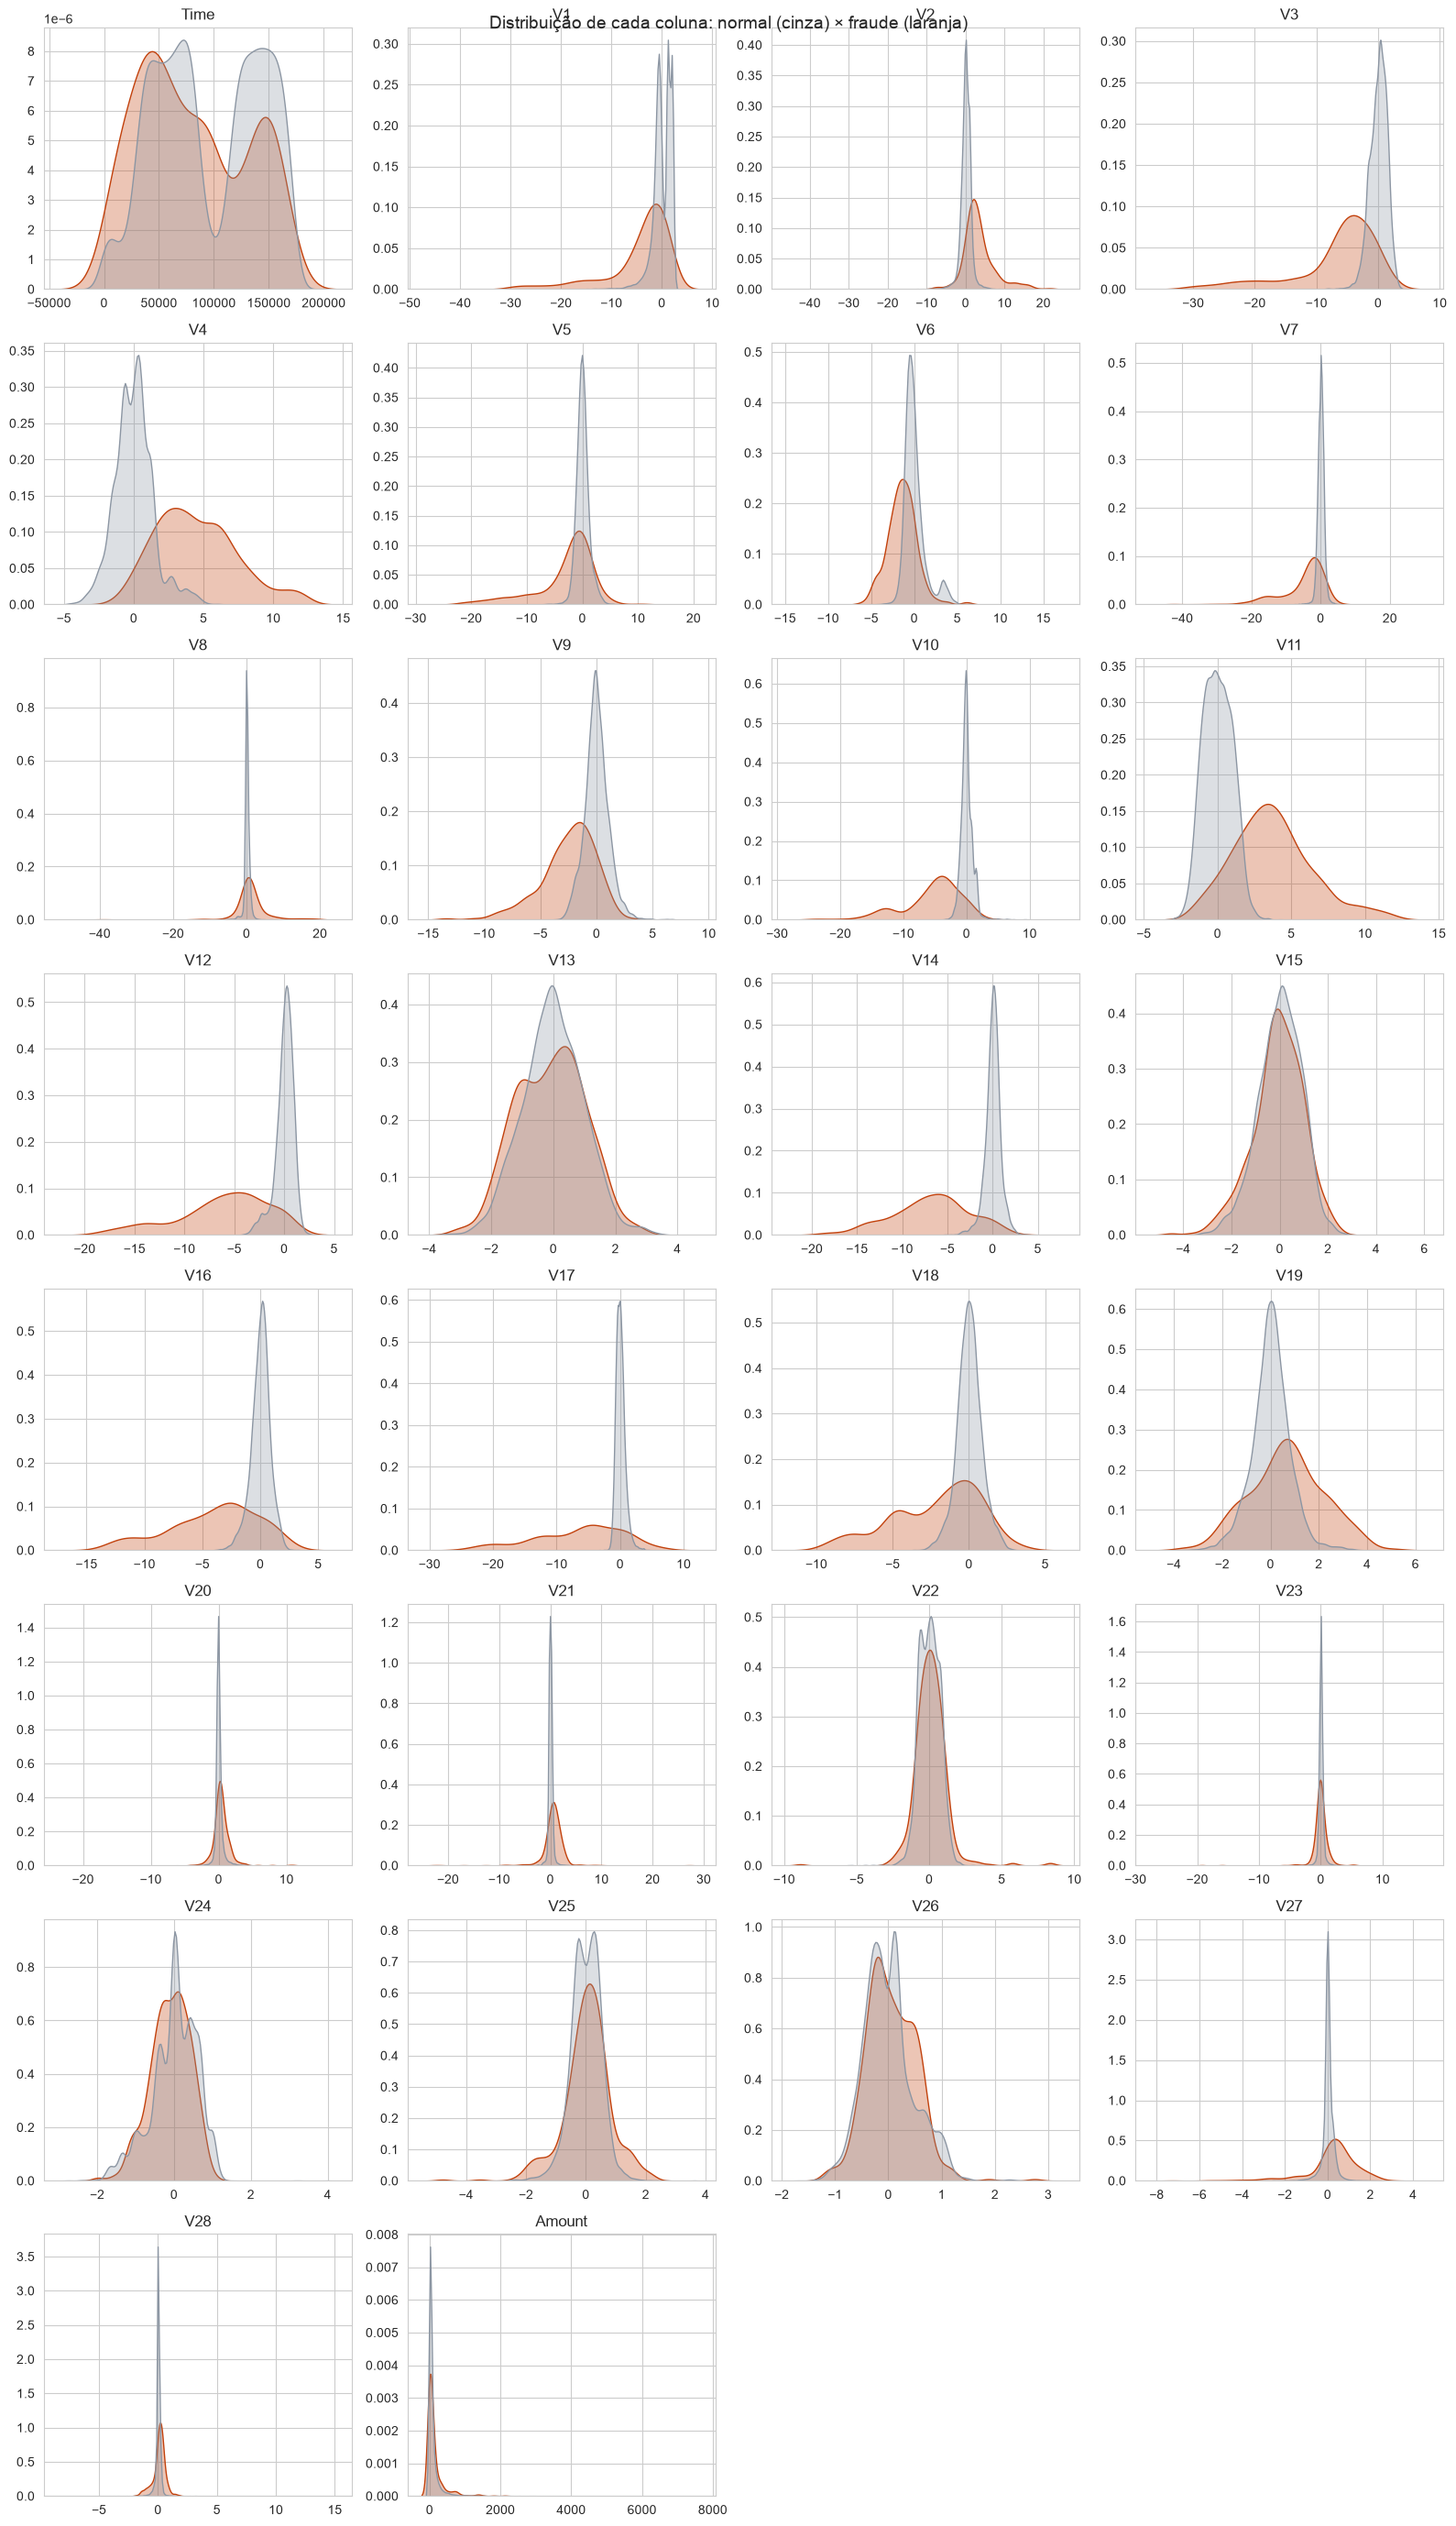

In [8]:
normais_explo = df[df["Class"] == 0]
amostra_explo = pd.concat([
    normais_explo.sample(n=min(20_000, len(normais_explo)), random_state=RANDOM_STATE),
    df[df["Class"] == 1],
])
colunas_explo = [c for c in df.columns if c != "Class"]

fig, eixos = plt.subplots(8, 4, figsize=(16, 28))
for eixo, coluna in zip(eixos.flat, colunas_explo):
    sns.kdeplot(data=amostra_explo, x=coluna, hue="Class", common_norm=False,
                palette=paleta, fill=True, alpha=0.3, legend=False,
                warn_singular=False, ax=eixo)
    eixo.set_title(coluna)
    eixo.set_xlabel("")
    eixo.set_ylabel("")
for eixo in list(eixos.flat)[len(colunas_explo):]:
    eixo.axis("off")
fig.suptitle("Distribuição de cada coluna: normal (cinza) × fraude (laranja)", fontsize=14)
plt.tight_layout()
plt.savefig(PASTA_RESULTADOS / "distribuicao_colunas.png", dpi=120)
plt.show()

**O que observar:** nas colunas em que as duas curvas ficam bem separadas, os valores das fraudes são diferentes dos normais, e a coluna ajuda a detectar fraude. Nas colunas em que as curvas se sobrepõem, a coluna diz pouco. Guarde quais colunas se separam: a seleção de features na seção 8 deve apontar as mesmas.

# <a id="6"></a>6. Divisão dos dados

Os dados são divididos **antes de qualquer cálculo**, para que nada usado na avaliação participe do aprendizado (isso seria vazamento de dados).

| Conjunto | Parte | Uso |
| --- | --- | --- |
| Treino | 60% | O modelo aprende e o ranking de colunas é calculado |
| Validação | 20% | Comparar as opções e escolher os finalistas |
| Apresentação | 20% | Avaliação final, usada uma única vez |

- **Dois splits:** o primeiro separa 20% para a apresentação. O segundo divide os 80% restantes com `test_size=0.25`, e 25% de 80% dá os 20% da validação.
- **`stratify`:** mantém a mesma proporção de fraude nas três partes.
- **`random_state`:** o sorteio sai sempre igual.

In [9]:
X = df.drop(columns=["Class"])
y = df["Class"]

X_resto, X_apres, y_resto, y_apres = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
X_treino, X_val, y_treino, y_val = train_test_split(
    X_resto, y_resto, test_size=0.25, stratify=y_resto, random_state=RANDOM_STATE)

pd.DataFrame({
    "linhas": [len(y_treino), len(y_val), len(y_apres)],
    "fraudes": [y_treino.sum(), y_val.sum(), y_apres.sum()],
    "% fraude": [y_treino.mean() * 100, y_val.mean() * 100, y_apres.mean() * 100],
}, index=["Treino", "Validação", "Apresentação"]).round(3)

,linhas,fraudes,% fraude
Treino,170235,284,0.167
Validação,56745,94,0.166
Apresentação,56746,95,0.167


# <a id="7"></a>7. Pré-processamento

A regra é: **`fit` só no treino, `transform` em tudo**. O `fit` é quando a ferramenta aprende (média, desvio, direções do PCA). O `transform` aplica o que foi aprendido. Validação e apresentação só recebem o `transform`, como transações novas num sistema real.

1. **`Time` e `Amount` viram `V29` e `V30`**, com padronização e PCA, para ficarem no mesmo padrão das outras colunas.
2. **As 30 colunas são padronizadas** (média 0, desvio 1). O LOF mede distâncias, e sem isso colunas com números maiores pesariam mais. O Isolation Forest não precisa disso, mas recebe os mesmos dados para a comparação ser justa.

In [10]:
scaler_ta = StandardScaler().fit(X_treino[["Time", "Amount"]])
pca_ta = PCA(n_components=2, random_state=RANDOM_STATE).fit(
    scaler_ta.transform(X_treino[["Time", "Amount"]]))

def transformar_time_amount(X_parte):
    X_parte = X_parte.copy()
    novos = pca_ta.transform(scaler_ta.transform(X_parte[["Time", "Amount"]]))
    X_parte["V29"] = novos[:, 0]
    X_parte["V30"] = novos[:, 1]
    return X_parte.drop(columns=["Time", "Amount"])

X_treino_t = transformar_time_amount(X_treino)
X_val_t = transformar_time_amount(X_val)
X_apres_t = transformar_time_amount(X_apres)

scaler_geral = StandardScaler().fit(X_treino_t)

def escalar(X_parte):
    return pd.DataFrame(scaler_geral.transform(X_parte),
                        columns=X_parte.columns, index=X_parte.index)

X_treino_p = escalar(X_treino_t)
X_val_p = escalar(X_val_t)
X_apres_p = escalar(X_apres_t)

print("Formatos:", X_treino_p.shape, X_val_p.shape, X_apres_p.shape)
pd.DataFrame({
    "média treino": X_treino_p.mean(), "desvio treino": X_treino_p.std(),
    "média validação": X_val_p.mean(), "desvio validação": X_val_p.std(),
}).round(2).head(8)

Formatos: (170235, 30) (56745, 30) (56746, 30)


,média treino,desvio treino,média validação,desvio validação
V1,0.0,1.0,0.00,0.99
V2,-0.0,1.0,-0.00,0.98
V3,0.0,1.0,-0.01,1.01
V4,-0.0,1.0,-0.00,1.00
V5,-0.0,1.0,-0.00,0.99
V6,0.0,1.0,0.00,1.00
V7,-0.0,1.0,-0.01,1.01
V8,0.0,1.0,-0.00,1.01


**A conferência:** no treino, as colunas ficam com média exatamente 0 e desvio 1. Na validação, ficam perto disso, mas não exatas. Essa pequena diferença é a prova de que a validação não participou do aprendizado.

# <a id="8"></a>8. Seleção de features

Nem toda coluna ajuda a detectar fraude, e colunas inúteis podem atrapalhar. As colunas são ordenadas pela **informação mútua** com a `Class`, calculada **só no treino**.

**Informação mútua** mede quanto saber o valor de uma coluna diminui a dúvida sobre ser fraude. Vale 0 quando a coluna não diz nada e cresce quanto mais ela ajuda. Ao contrário da correlação, capta também relações não lineares. A correlação é calculada junto, só para comparação.

Os valores saem pequenos de propósito: a informação mútua não passa da incerteza total da `Class`, que é baixíssima com 0,17% de fraude. O que importa é a ordem.

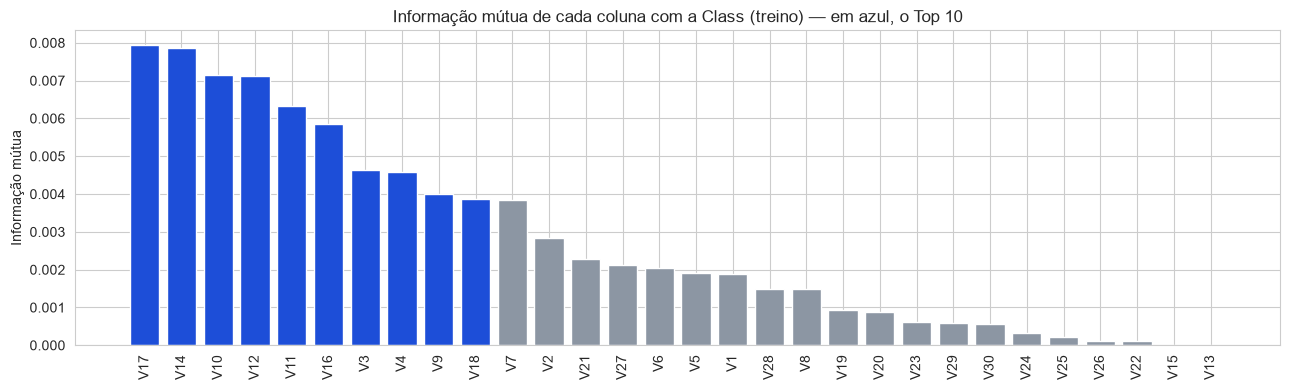

,info_mutua,corr_abs,pos_mi,pos_corr
V17,0.0079,0.3197,1,1
V14,0.0079,0.2987,2,2
V10,0.0071,0.2080,3,4
V12,0.0071,0.2507,4,3
V11,0.0063,0.1507,5,8
V16,0.0058,0.1871,6,6
V3,0.0046,0.1890,7,5
V4,0.0046,0.1269,8,9
V9,0.0040,0.0930,9,13
V18,0.0039,0.1050,10,10


In [11]:
mi = mutual_info_classif(X_treino_p, y_treino, random_state=RANDOM_STATE)
corr = X_treino_p.corrwith(y_treino).abs()

ranking = pd.DataFrame({"info_mutua": mi, "corr_abs": corr}, index=X_treino_p.columns)
ranking["pos_mi"] = ranking["info_mutua"].rank(ascending=False, method="first").astype(int)
ranking["pos_corr"] = ranking["corr_abs"].rank(ascending=False, method="first").astype(int)
ranking = ranking.sort_values("pos_mi")
ranking.to_csv(PASTA_RESULTADOS / "ranking_colunas.csv")

fig, ax = plt.subplots(figsize=(13, 4))
cores_barras = [CORES["Isolation Forest"] if p <= 10 else CORES["Normal"] for p in ranking["pos_mi"]]
ax.bar(ranking.index, ranking["info_mutua"], color=cores_barras)
ax.set_title("Informação mútua de cada coluna com a Class (treino) — em azul, o Top 10")
ax.set_ylabel("Informação mútua")
plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig(PASTA_RESULTADOS / "ranking_info_mutua.png", dpi=150)
plt.show()

ranking.head(15).round(4)

**O que observar:**

- Compare `pos_mi` e `pos_corr`. Se as primeiras posições coincidem, os dois critérios concordam e a seleção é estável.
- Uma coluna bem colocada na informação mútua e mal colocada na correlação tem relação **não linear** com a fraude. É o caso que justifica usar a informação mútua como critério principal.
- Compare com a seção 5.4: as colunas do topo devem ser as que tinham as curvas mais separadas.

**Quantas colunas manter?** Um corte no olho seria arbitrário. Em vez disso, testamos vários subconjuntos (Top 5, 10, 15, 20 e todas, mais Top 10 e 15 da correlação, para comparar) e deixamos o desempenho na validação decidir.

In [12]:
top_mi = list(ranking.sort_values("pos_mi").index)
top_corr = list(ranking.sort_values("pos_corr").index)

experimentos = {
    "Sem seleção": top_mi,
    "MI-5": top_mi[:5],
    "MI-10": top_mi[:10],
    "MI-15": top_mi[:15],
    "MI-20": top_mi[:20],
    "Corr-10": top_corr[:10],
    "Corr-15": top_corr[:15],
}

for nome, colunas in experimentos.items():
    print(f"{nome:12} ({len(colunas):2} colunas): {', '.join(colunas[:10])}{' ...' if len(colunas) > 10 else ''}")

Sem seleção  (30 colunas): V17, V14, V10, V12, V11, V16, V3, V4, V9, V18 ...
MI-5         ( 5 colunas): V17, V14, V10, V12, V11
MI-10        (10 colunas): V17, V14, V10, V12, V11, V16, V3, V4, V9, V18
MI-15        (15 colunas): V17, V14, V10, V12, V11, V16, V3, V4, V9, V18 ...
MI-20        (20 colunas): V17, V14, V10, V12, V11, V16, V3, V4, V9, V18 ...
Corr-10      (10 colunas): V17, V14, V12, V10, V3, V16, V7, V11, V4, V18
Corr-15      (15 colunas): V17, V14, V12, V10, V3, V16, V7, V11, V4, V18 ...


# <a id="9"></a>9. Modelos

Os dois modelos seguem as mesmas regras, para a comparação ser justa:

- **Treinam só com transações normais**, numa mesma amostra de 50 mil do treino. O LOF ficaria lento demais com todas.
- **`contamination` igual à proporção de fraude do treino.** É ele que define o limite: o modelo marca como suspeita a fração mais estranha das transações.
- **São medidos na validação**, com as mesmas métricas.

As duas funções abaixo evitam repetir código: uma treina e pontua, a outra calcula as métricas.

- `predict` devolve -1 para anomalia e 1 para normal. Convertemos para 1 = fraude e 0 = normal, o formato da `Class`.
- `score_samples` dá o grau de normalidade, em que menor é mais estranho. O sinal de menos inverte, para que **maior signifique mais suspeito**.

In [13]:
CONTAMINACAO = y_treino.mean()

normais_treino = X_treino_p[y_treino == 0]
amostra_normais = normais_treino.sample(n=min(50_000, len(normais_treino)), random_state=RANDOM_STATE)
print(f"contamination = {CONTAMINACAO:.5f} | amostra de treino: {len(amostra_normais):,} transações normais")

def treinar_e_pontuar(modelo, X_treinar, X_avaliar):
    inicio = time.time()
    modelo.fit(X_treinar)
    y_pred = (modelo.predict(X_avaliar) == -1).astype(int)
    score = -modelo.score_samples(X_avaliar)
    return y_pred, score, time.time() - inicio

def avaliar(y_real, y_pred, score):
    return {
        "acuracia": accuracy_score(y_real, y_pred),
        "precision": precision_score(y_real, y_pred, zero_division=0),
        "recall": recall_score(y_real, y_pred),
        "f1": f1_score(y_real, y_pred),
        "jaccard": jaccard_score(y_real, y_pred),
        "auprc": average_precision_score(y_real, score),
        "roc_auc": roc_auc_score(y_real, score),
    }

def plotar_scores(score, y_real, limite, titulo, arquivo, log=False):
    valores = np.log10(score) if log else score
    corte = np.log10(limite) if log else limite
    bins = np.linspace(np.percentile(valores, 0.1), valores.max(), 80)
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.hist(valores[y_real.values == 0], bins=bins, density=True, alpha=0.6,
            color=CORES["Normal"], label="Normal")
    ax.hist(valores[y_real.values == 1], bins=bins, density=True, alpha=0.6,
            color=CORES["Fraude"], label="Fraude")
    ax.axvline(corte, color="black", linestyle="--", label="Limite de decisão")
    ax.set_title(titulo)
    ax.set_xlabel("log10 do score de anomalia" if log else "Score de anomalia (maior = mais suspeito)")
    ax.set_ylabel("Densidade")
    ax.legend()
    plt.tight_layout()
    plt.savefig(PASTA_RESULTADOS / arquivo, dpi=150)
    plt.show()

contamination = 0.00167 | amostra de treino: 50,000 transações normais


## 9.1 Isolation Forest

**Como funciona:** o modelo cria várias árvores. Cada uma sorteia uma coluna e um ponto de corte, e vai dividindo os dados até cada transação ficar sozinha. Transações estranhas ficam isoladas com **poucos cortes**, porque estão longe das outras. O score é a média de cortes em todas as árvores: quanto menos cortes, mais suspeita.

**Parâmetro testado:** `n_estimators`, o número de árvores (50, 100, 200 e 500). Mais árvores deixam o score mais estável, mas a partir de certo ponto só deixam o modelo mais lento.

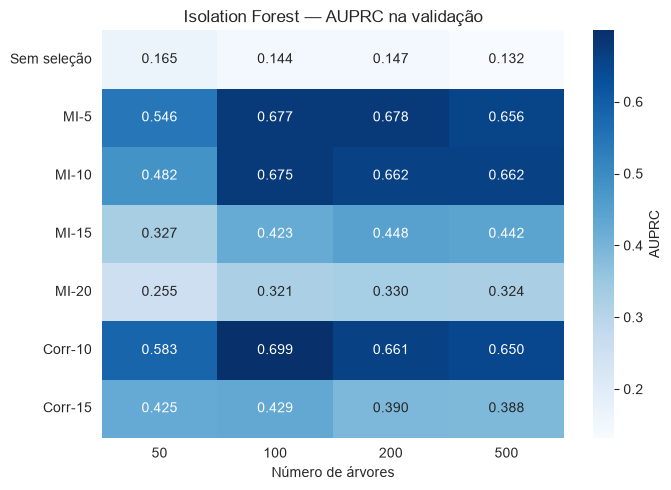

experimento     Corr-10
arvores             100
precision      0.427027
recall         0.840426
f1             0.566308
auprc          0.699087
Name: 21, dtype: object

In [14]:
ARVORES = [50, 100, 200, 500]

linhas = []
for nome_exp, colunas in experimentos.items():
    for arvores in ARVORES:
        modelo = IsolationForest(n_estimators=arvores, contamination=CONTAMINACAO,
                                 random_state=RANDOM_STATE, n_jobs=-1)
        y_pred, score, segundos = treinar_e_pontuar(modelo, amostra_normais[colunas], X_val_p[colunas])
        linhas.append({"experimento": nome_exp, "k": len(colunas), "arvores": arvores,
                       **avaliar(y_val, y_pred, score), "segundos": round(segundos, 1)})

res_if = pd.DataFrame(linhas)
res_if.to_csv(PASTA_RESULTADOS / "validacao_isolation_forest.csv", index=False)

tabela_if = res_if.pivot(index="experimento", columns="arvores", values="auprc").loc[list(experimentos)]
plt.figure(figsize=(7, 5))
sns.heatmap(tabela_if, annot=True, fmt=".3f", cmap="Blues", cbar_kws={"label": "AUPRC"})
plt.title("Isolation Forest — AUPRC na validação")
plt.xlabel("Número de árvores")
plt.ylabel("")
plt.tight_layout()
plt.savefig(PASTA_RESULTADOS / "validacao_isolation_forest.png", dpi=150)
plt.show()

melhor_if = res_if.loc[res_if["auprc"].idxmax()]
melhor_if[["experimento", "arvores", "precision", "recall", "f1", "auprc"]]

**O que observar:**

- **Linhas (colunas usadas):** compare "Sem seleção" com os Top K. Como o Isolation Forest sorteia a coluna de cada corte, colunas inúteis desperdiçam cortes, e a seleção costuma fazer muita diferença.
- **Colunas (árvores):** se os valores mudam pouco de 100 para 500, mais árvores não compensam o custo.

### Como o Isolation Forest separa as classes

O histograma mostra o score da melhor configuração na validação. Quanto mais as fraudes (laranja) ficam à direita do limite e as normais (cinza) à esquerda, melhor o modelo.

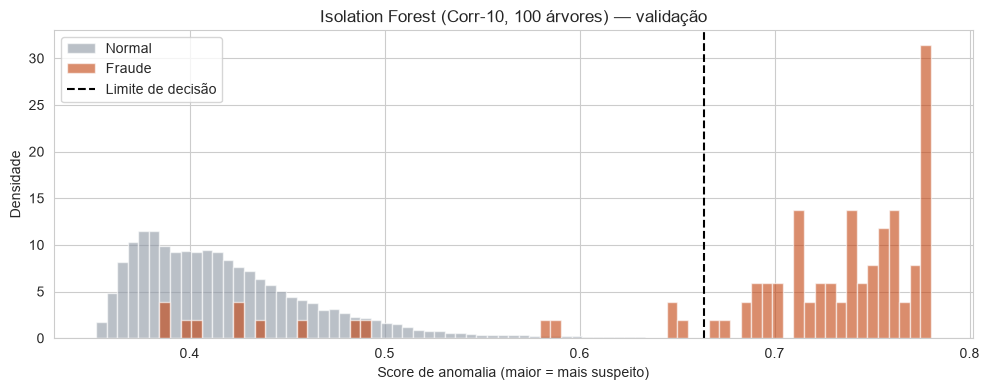

In [15]:
colunas_if = experimentos[melhor_if["experimento"]]
modelo_if_val = IsolationForest(n_estimators=int(melhor_if["arvores"]), contamination=CONTAMINACAO,
                                random_state=RANDOM_STATE, n_jobs=-1)
_, score_if_val, _ = treinar_e_pontuar(modelo_if_val, amostra_normais[colunas_if], X_val_p[colunas_if])

plotar_scores(score_if_val, y_val, -modelo_if_val.offset_,
              f"Isolation Forest ({melhor_if['experimento']}, {int(melhor_if['arvores'])} árvores) — validação",
              "scores_isolation_forest.png")

## 9.2 Local Outlier Factor (LOF)

**Como funciona:** para cada transação, o LOF olha as `k` vizinhas mais próximas e compara a densidade em volta dela com a densidade em volta das vizinhas. Uma transação numa região bem mais vazia que a das vizinhas é suspeita.

**Cuidados específicos:**

- **`novelty=True`:** sem isso, o LOF só avalia os dados em que foi treinado e não consegue julgar transações novas.
- **Duplicados por subconjunto:** mesmo com o dataset limpo, ao usar só 5 ou 10 colunas, transações diferentes podem ficar iguais. Elas são removidas do treino do LOF dentro de cada experimento.

**Parâmetro testado:** `n_neighbors`, o número de vizinhos (20, 50 e 100). Com poucos vizinhos, um grupo de fraudes parecidas entre si pode parecer uma região densa, ou seja, normal.

Sem seleção: ok
MI-5: ok
MI-10: ok
MI-15: ok
MI-20: ok
Corr-10: ok
Corr-15: ok


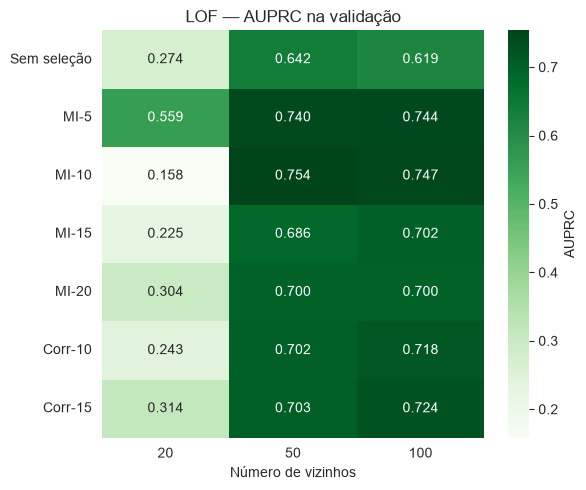

experimento       MI-10
vizinhos             50
precision      0.435484
recall         0.861702
f1             0.578571
auprc          0.753539
Name: 7, dtype: object

In [16]:
VIZINHOS = [20, 50, 100]

linhas = []
for nome_exp, colunas in experimentos.items():
    treino_lof = amostra_normais[colunas].drop_duplicates()
    for vizinhos in VIZINHOS:
        modelo = LocalOutlierFactor(n_neighbors=vizinhos, novelty=True,
                                    contamination=CONTAMINACAO, n_jobs=-1)
        y_pred, score, segundos = treinar_e_pontuar(modelo, treino_lof, X_val_p[colunas])
        linhas.append({"experimento": nome_exp, "k": len(colunas), "vizinhos": vizinhos,
                       "linhas_treino": len(treino_lof),
                       **avaliar(y_val, y_pred, score), "segundos": round(segundos, 1)})
    print(f"{nome_exp}: ok")

res_lof = pd.DataFrame(linhas)
res_lof.to_csv(PASTA_RESULTADOS / "validacao_lof.csv", index=False)

tabela_lof = res_lof.pivot(index="experimento", columns="vizinhos", values="auprc").loc[list(experimentos)]
plt.figure(figsize=(6, 5))
sns.heatmap(tabela_lof, annot=True, fmt=".3f", cmap="Greens", cbar_kws={"label": "AUPRC"})
plt.title("LOF — AUPRC na validação")
plt.xlabel("Número de vizinhos")
plt.ylabel("")
plt.tight_layout()
plt.savefig(PASTA_RESULTADOS / "validacao_lof.png", dpi=150)
plt.show()

melhor_lof = res_lof.loc[res_lof["auprc"].idxmax()]
melhor_lof[["experimento", "vizinhos", "precision", "recall", "f1", "auprc"]]

**O que observar:** compare a coluna de 20 vizinhos com as de 50 e 100. Se a diferença for grande, o número de vizinhos é o parâmetro decisivo do LOF neste problema.

### Como o LOF separa as classes

O score do LOF pode ter valores muito altos para algumas fraudes, então o eixo usa escala logarítmica (log10) para o gráfico ficar legível.

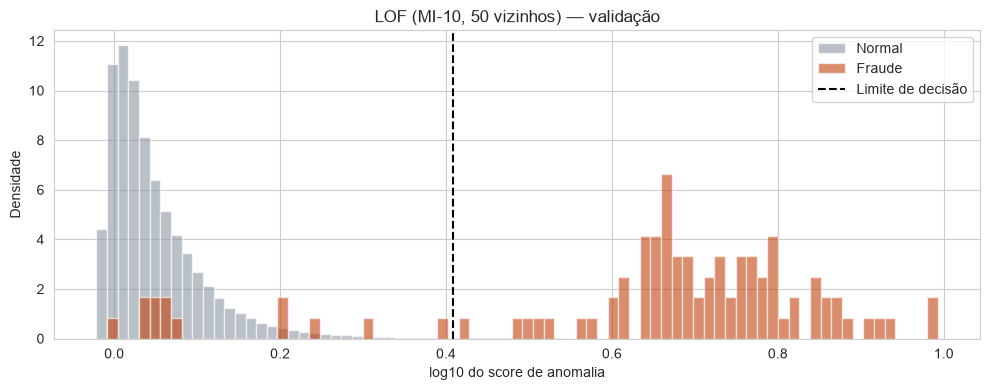

In [17]:
colunas_lof = experimentos[melhor_lof["experimento"]]
modelo_lof_val = LocalOutlierFactor(n_neighbors=int(melhor_lof["vizinhos"]), novelty=True,
                                    contamination=CONTAMINACAO, n_jobs=-1)
_, score_lof_val, _ = treinar_e_pontuar(modelo_lof_val, amostra_normais[colunas_lof].drop_duplicates(),
                                        X_val_p[colunas_lof])

plotar_scores(score_lof_val, y_val, -modelo_lof_val.offset_,
              f"LOF ({melhor_lof['experimento']}, {int(melhor_lof['vizinhos'])} vizinhos) — validação",
              "scores_lof.png", log=True)

## 9.3 Comparação na validação

O gráfico mostra a melhor AUPRC de cada modelo em cada subconjunto de colunas. É o resumo de todos os experimentos.

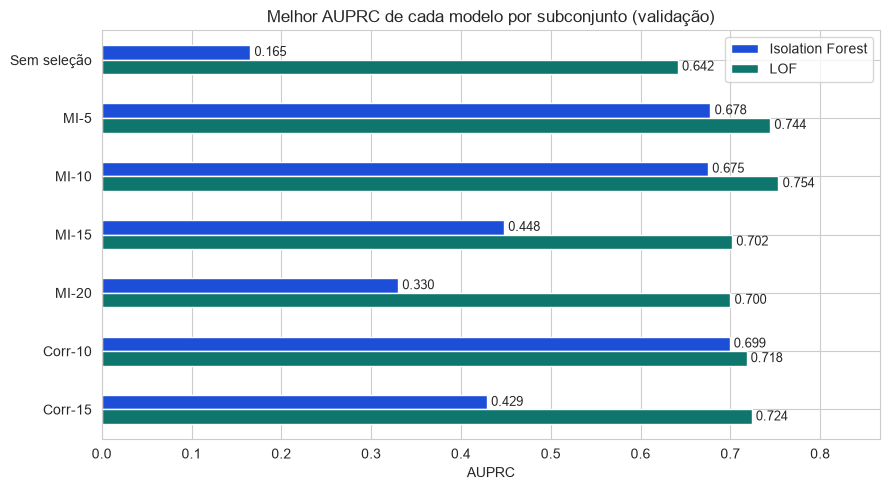

,Isolation Forest,LOF
experimento,,
Sem seleção,0.165,0.642
MI-5,0.678,0.744
MI-10,0.675,0.754
MI-15,0.448,0.702
MI-20,0.330,0.700
Corr-10,0.699,0.718
Corr-15,0.429,0.724


In [18]:
melhor_por_exp = pd.DataFrame({
    "Isolation Forest": res_if.groupby("experimento")["auprc"].max(),
    "LOF": res_lof.groupby("experimento")["auprc"].max(),
}).loc[list(experimentos)]

ax = melhor_por_exp.plot(kind="barh", figsize=(9, 5),
                         color=[CORES["Isolation Forest"], CORES["LOF"]])
ax.invert_yaxis()
ax.set_title("Melhor AUPRC de cada modelo por subconjunto (validação)")
ax.set_xlabel("AUPRC")
ax.set_ylabel("")
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3, fontsize=9)
ax.set_xlim(0, melhor_por_exp.max().max() * 1.15)
plt.tight_layout()
plt.savefig(PASTA_RESULTADOS / "comparacao_validacao.png", dpi=150)
plt.show()

melhor_por_exp.round(3)

### Os finalistas

Os finalistas foram definidos na primeira rodada de experimentos, **antes de olhar o conjunto de apresentação**, e ficam fixos aqui para a avaliação final continuar honesta. A célula abaixo mostra lado a lado o finalista e a melhor configuração desta execução, por transparência.

- **Isolation Forest:** Top 10 da informação mútua, 200 árvores.
- **LOF:** Top 5 da informação mútua, 50 vizinhos. Empatou na prática com o Top 10 com 100 vizinhos e foi escolhido por ser mais simples e mais rápido.

In [19]:
FINALISTAS = {
    "Isolation Forest": {"experimento": "MI-10", "parametro": 200},
    "LOF": {"experimento": "MI-5", "parametro": 50},
}

pd.DataFrame({
    "finalista": [f"{FINALISTAS['Isolation Forest']['experimento']}, {FINALISTAS['Isolation Forest']['parametro']} árvores",
                  f"{FINALISTAS['LOF']['experimento']}, {FINALISTAS['LOF']['parametro']} vizinhos"],
    "AUPRC do finalista": [
        res_if.query("experimento == @FINALISTAS['Isolation Forest']['experimento'] and arvores == @FINALISTAS['Isolation Forest']['parametro']")["auprc"].iloc[0],
        res_lof.query("experimento == @FINALISTAS['LOF']['experimento'] and vizinhos == @FINALISTAS['LOF']['parametro']")["auprc"].iloc[0],
    ],
    "melhor desta execução": [f"{melhor_if['experimento']}, {int(melhor_if['arvores'])} árvores",
                              f"{melhor_lof['experimento']}, {int(melhor_lof['vizinhos'])} vizinhos"],
    "AUPRC do melhor": [melhor_if["auprc"], melhor_lof["auprc"]],
}, index=["Isolation Forest", "LOF"]).round(3)

,finalista,AUPRC do finalista,melhor desta execução,AUPRC do melhor
Isolation Forest,"MI-10, 200 árvores",0.662,"Corr-10, 100 árvores",0.699
LOF,"MI-5, 50 vizinhos",0.740,"MI-10, 50 vizinhos",0.754


# <a id="10"></a>10. Limite de decisão

O `contamination` faz o modelo marcar como suspeitas cerca de 0,17% das transações. Mas o limite é uma escolha de negócio: um banco pode preferir revisar mais transações para pegar mais fraudes, aceitando mais falsos alarmes.

Aqui, os finalistas são treinados e usados para ordenar as transações da **validação** da mais suspeita para a menos suspeita. Para cada fatia revisada (as 0,1% mais suspeitas, as 0,25% e assim por diante), calculamos quantas fraudes seriam pegas e a precisão.

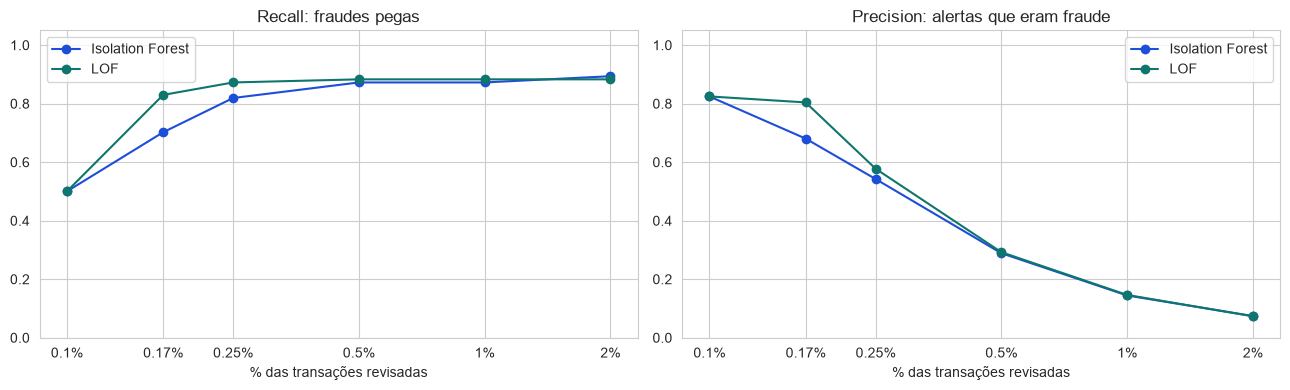

,modelo,% revisado,alertas,fraudes pegas,recall,precision
0,Isolation Forest,0.10,57,47,0.500,0.825
1,Isolation Forest,0.17,97,66,0.702,0.680
2,Isolation Forest,0.25,142,77,0.819,0.542
3,Isolation Forest,0.50,284,82,0.872,0.289
4,Isolation Forest,1.00,568,82,0.872,0.144
5,Isolation Forest,2.00,1135,84,0.894,0.074
6,LOF,0.10,57,47,0.500,0.825
7,LOF,0.17,97,78,0.830,0.804
8,LOF,0.25,142,82,0.872,0.577
9,LOF,0.50,284,83,0.883,0.292


In [20]:
def criar_finalista(nome):
    config = FINALISTAS[nome]
    colunas = experimentos[config["experimento"]]
    if nome == "Isolation Forest":
        modelo = IsolationForest(n_estimators=config["parametro"], contamination=CONTAMINACAO,
                                 random_state=RANDOM_STATE, n_jobs=-1)
        treino = amostra_normais[colunas]
    else:
        modelo = LocalOutlierFactor(n_neighbors=config["parametro"], novelty=True,
                                    contamination=CONTAMINACAO, n_jobs=-1)
        treino = amostra_normais[colunas].drop_duplicates()
    modelo.fit(treino)
    return modelo, colunas

modelos_finais = {nome: criar_finalista(nome) for nome in FINALISTAS}

FATIAS = [0.001, 0.0017, 0.0025, 0.005, 0.01, 0.02]
linhas = []
for nome, (modelo, colunas) in modelos_finais.items():
    score = -modelo.score_samples(X_val_p[colunas])
    for fatia in FATIAS:
        corte = np.quantile(score, 1 - fatia)
        y_pred = (score >= corte).astype(int)
        linhas.append({"modelo": nome, "% revisado": fatia * 100, "alertas": y_pred.sum(),
                       "fraudes pegas": int(((y_pred == 1) & (y_val.values == 1)).sum()),
                       "recall": recall_score(y_val, y_pred),
                       "precision": precision_score(y_val, y_pred, zero_division=0)})

limites = pd.DataFrame(linhas)
limites.to_csv(PASTA_RESULTADOS / "analise_limite.csv", index=False)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
for nome, grupo in limites.groupby("modelo"):
    ax1.plot(grupo["% revisado"], grupo["recall"], marker="o", color=CORES[nome], label=nome)
    ax2.plot(grupo["% revisado"], grupo["precision"], marker="o", color=CORES[nome], label=nome)
ax1.set_title("Recall: fraudes pegas")
ax2.set_title("Precision: alertas que eram fraude")
for ax in (ax1, ax2):
    ax.set_xscale("log")
    ax.set_xticks(limites["% revisado"].unique())
    ax.set_xticklabels([f"{v:g}%" for v in limites["% revisado"].unique()])
    ax.set_xlabel("% das transações revisadas")
    ax.set_ylim(0, 1.05)
    ax.legend()
plt.tight_layout()
plt.savefig(PASTA_RESULTADOS / "analise_limite.png", dpi=150)
plt.show()

limites.round(3)

**O que observar:** quanto maior a fatia revisada, mais fraudes são pegas (recall sobe) e maior a parte dos alertas que são alarmes falsos (precision cai). É a troca que o banco precisa decidir. Por exemplo: revisar 1% das transações pega quantas fraudes a mais do que revisar 0,17%? Esse custo compensa?

Para a avaliação final, o limite continua o do `contamination`, que foi definido antes de olhar os resultados.

# <a id="11"></a>11. Avaliação final

Os dois finalistas são avaliados **uma única vez** no conjunto de apresentação, que ficou guardado desde a divisão. Como ele não participou de nenhuma escolha, este é o resultado oficial do projeto.

**Regra:** depois de rodar esta seção, não se volta para mudar colunas, vizinhos ou árvores. Se mudar, a apresentação passa a influenciar a escolha e deixa de ser um teste honesto.

In [21]:
linhas, scores_final, preds_final = [], {}, {}
for nome, (modelo, colunas) in modelos_finais.items():
    y_pred = (modelo.predict(X_apres_p[colunas]) == -1).astype(int)
    score = -modelo.score_samples(X_apres_p[colunas])
    scores_final[nome], preds_final[nome] = score, y_pred

    fraude = y_apres.values == 1
    valor_total = X_apres.loc[fraude, "Amount"].sum()
    valor_pego = X_apres.loc[fraude & (y_pred == 1), "Amount"].sum()
    linhas.append({"modelo": nome, **avaliar(y_apres, y_pred, score),
                   "fraudes pegas": f"{int((fraude & (y_pred == 1)).sum())} de {int(fraude.sum())}",
                   "falsos alarmes": int(((~fraude) & (y_pred == 1)).sum()),
                   "% do valor fraudado pego": valor_pego / valor_total * 100})

final = pd.DataFrame(linhas).set_index("modelo")
final.to_csv(PASTA_RESULTADOS / "avaliacao_final.csv")
final.round(3)

,acuracia,precision,recall,f1,jaccard,auprc,roc_auc,fraudes pegas,falsos alarmes,% do valor fraudado pego
modelo,,,,,,,,,,
Isolation Forest,0.997,0.377,0.758,0.503,0.336,0.519,0.937,72 de 95,119,72.577
LOF,0.998,0.468,0.768,0.582,0.410,0.665,0.930,73 de 95,83,74.316


**Como ler cada métrica:**

- **Acurácia:** vai sair perto de 99,8% para os dois. Parece ótimo, mas chutar "normal" para tudo também daria isso. É mostrada para explicar por que engana.
- **Precision e recall:** a parte das suspeitas que era fraude e a parte das fraudes que foi pega.
- **Jaccard:** acertos de fraude divididos por tudo o que é fraude ou foi marcado como fraude. Ignora os acertos fáceis, por isso é mais exigente.
- **AUPRC:** a métrica principal. Não depende do limite de corte.
- **ROC AUC:** tende a sair alta (acima de 0,9) porque, com tantas transações normais, poucos falsos alarmes viram uma taxa minúscula. A AUPRC é mais honesta para fraude rara.
- **% do valor fraudado pego:** traduz o resultado em dinheiro.

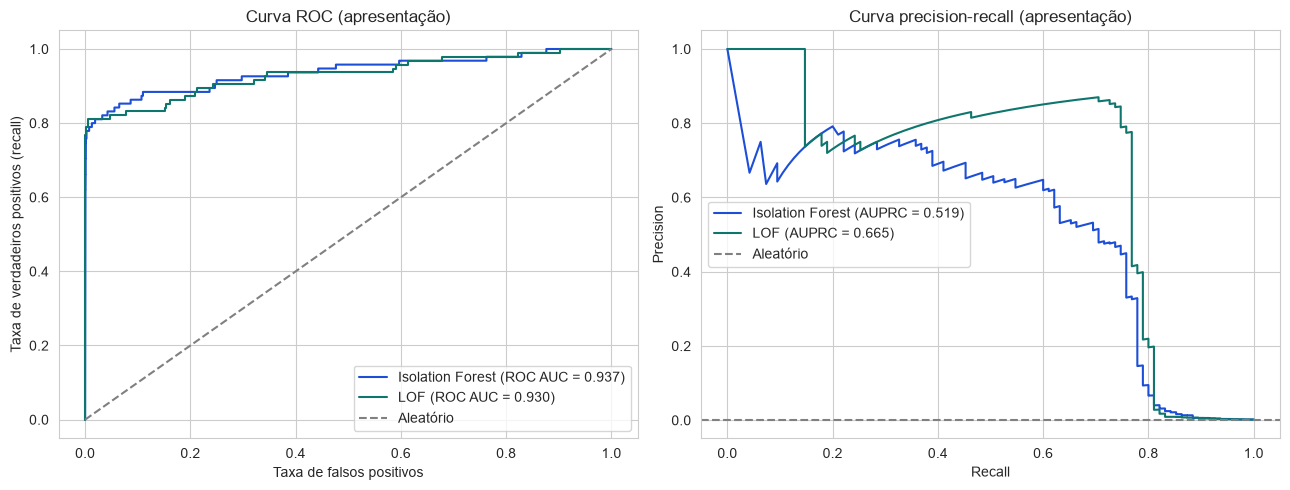

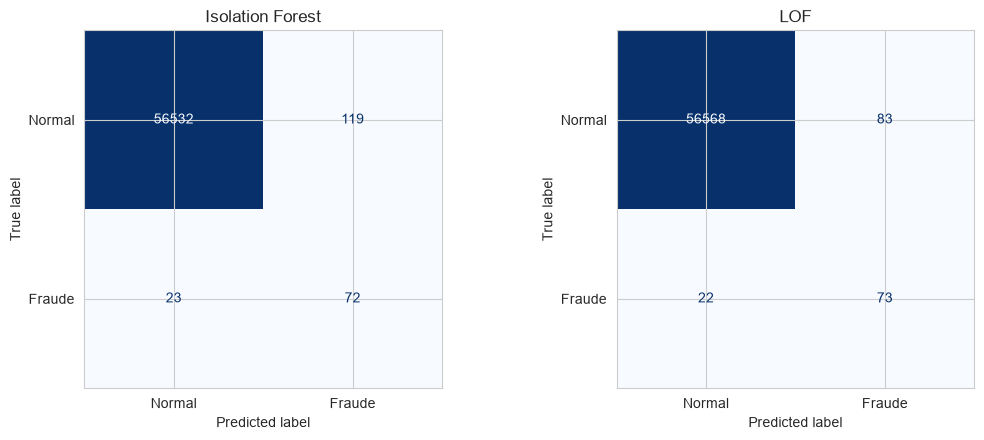

In [22]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
for nome, score in scores_final.items():
    fpr, tpr, _ = roc_curve(y_apres, score)
    precisao, revocacao, _ = precision_recall_curve(y_apres, score)
    ax1.plot(fpr, tpr, color=CORES[nome],
             label=f"{nome} (ROC AUC = {final.loc[nome, 'roc_auc']:.3f})")
    ax2.plot(revocacao, precisao, color=CORES[nome],
             label=f"{nome} (AUPRC = {final.loc[nome, 'auprc']:.3f})")
ax1.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Aleatório")
ax2.axhline(y_apres.mean(), linestyle="--", color="grey", label="Aleatório")
ax1.set_title("Curva ROC (apresentação)")
ax1.set_xlabel("Taxa de falsos positivos")
ax1.set_ylabel("Taxa de verdadeiros positivos (recall)")
ax2.set_title("Curva precision-recall (apresentação)")
ax2.set_xlabel("Recall")
ax2.set_ylabel("Precision")
for ax in (ax1, ax2):
    ax.legend()
plt.tight_layout()
plt.savefig(PASTA_RESULTADOS / "curvas_finais.png", dpi=150)
plt.show()

fig, eixos = plt.subplots(1, 2, figsize=(11, 4.5))
for eixo, (nome, y_pred) in zip(eixos, preds_final.items()):
    ConfusionMatrixDisplay.from_predictions(y_apres, y_pred, display_labels=["Normal", "Fraude"],
                                            cmap="Blues", colorbar=False, ax=eixo)
    eixo.set_title(nome)
plt.tight_layout()
plt.savefig(PASTA_RESULTADOS / "matrizes_confusao.png", dpi=150)
plt.show()

**Como ler a matriz de confusão:**

| | Previsto normal | Previsto fraude |
| --- | --- | --- |
| **Real normal** | Acerto (verdadeiro negativo) | Falso alarme (falso positivo) |
| **Real fraude** | Fraude que passou (falso negativo) | Fraude pega (verdadeiro positivo) |

O canto inferior direito é o que mais importa: fraudes pegas. O canto inferior esquerdo é o prejuízo: fraudes que passaram.

### Comparação entre treino, validação e apresentação

Mede os finalistas em cada conjunto, para verificar se o modelo foi bem só nos dados que já conhecia (overfitting). Resultados parecidos nos quatro conjuntos indicam que ele generaliza bem.

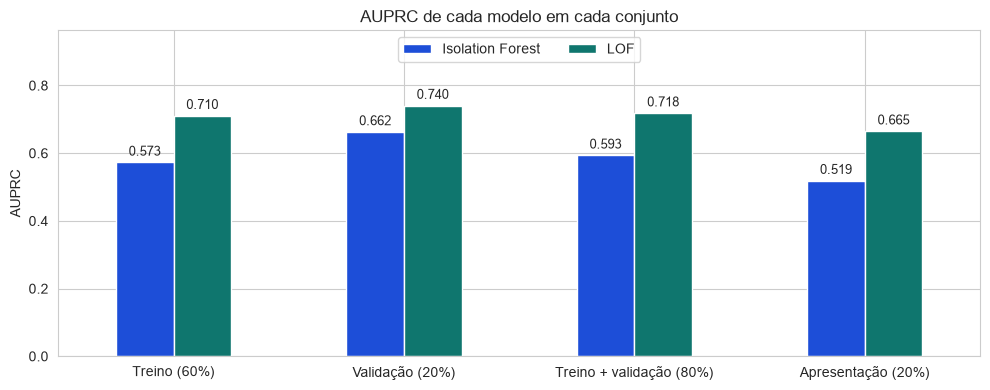

,modelo,conjunto,fraudes,precision,recall,f1,auprc
0,Isolation Forest,Treino (60%),284,0.400,0.750,0.521,0.573
1,Isolation Forest,Validação (20%),94,0.454,0.840,0.590,0.662
2,Isolation Forest,Treino + validação (80%),378,0.413,0.772,0.538,0.593
3,Isolation Forest,Apresentação (20%),95,0.377,0.758,0.503,0.519
4,LOF,Treino (60%),284,0.469,0.820,0.597,0.710
5,LOF,Validação (20%),94,0.483,0.883,0.624,0.740
6,LOF,Treino + validação (80%),378,0.472,0.836,0.604,0.718
7,LOF,Apresentação (20%),95,0.468,0.768,0.582,0.665


In [28]:
conjuntos = {
    "Treino (60%)": (X_treino_p, y_treino),
    "Validação (20%)": (X_val_p, y_val),
    "Treino + validação (80%)": (pd.concat([X_treino_p, X_val_p]), pd.concat([y_treino, y_val])),
    "Apresentação (20%)": (X_apres_p, y_apres),
}

linhas = []
for nome_modelo, (modelo, colunas) in modelos_finais.items():
    for nome_conjunto, (X_c, y_c) in conjuntos.items():
        y_pred = (modelo.predict(X_c[colunas]) == -1).astype(int)
        score = -modelo.score_samples(X_c[colunas])
        m = avaliar(y_c, y_pred, score)
        linhas.append({"modelo": nome_modelo, "conjunto": nome_conjunto, "fraudes": int(y_c.sum()),
                       "precision": m["precision"], "recall": m["recall"],
                       "f1": m["f1"], "auprc": m["auprc"]})

comparacao = pd.DataFrame(linhas)
comparacao.to_csv(PASTA_RESULTADOS / "comparacao_conjuntos.csv", index=False)

tabela = comparacao.pivot(index="conjunto", columns="modelo", values="auprc").loc[list(conjuntos)]
ax = tabela.plot(kind="bar", figsize=(10, 4), rot=0,
                 color=[CORES[m] for m in tabela.columns])
ax.set_title("AUPRC de cada modelo em cada conjunto")
ax.set_ylabel("AUPRC")
ax.set_xlabel("")
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3, fontsize=9)
ax.set_ylim(0, tabela.max().max() * 1.3)
ax.legend(title="", ncol=2, loc="upper center")
plt.tight_layout()
plt.savefig(PASTA_RESULTADOS / "comparacao_conjuntos.png", dpi=150)
plt.show()

comparacao.round(3)

**Como ler:**

- **Não há sinal de overfitting.** O desempenho no treino não é melhor que nos dados novos: Isolation Forest com AUPRC de 0,573 no treino e 0,519 na apresentação; LOF com 0,710 e 0,665.
- **A validação foi o conjunto com melhor resultado para os dois modelos** (0,662 e 0,740). Como as escolhas de colunas e parâmetros foram feitas olhando para ela, é esperado que saia um pouco otimista. Por isso o número oficial é o da apresentação.
- **A queda dos 80% (treino + validação) para os 20% da apresentação é moderada e parecida nos dois modelos:** -0,074 no Isolation Forest e -0,053 no LOF. Com cerca de 95 fraudes em cada conjunto, essa variação é esperada.
- **O LOF foi melhor nos quatro conjuntos**, o que mostra que a vantagem dele é consistente e não resultado de uma divisão favorável.
- **O recall é estável:** entre 75% e 84% no Isolation Forest e entre 77% e 88% no LOF.

**Cuidados na leitura:**

- **O recall do treino é justo:** os dois modelos treinaram só com transações normais e nunca viram nenhuma fraude.
- **O número oficial continua sendo o da apresentação**, porque é o único conjunto que não participou de nenhuma escolha.

# <a id="12"></a>12. Salvando o modelo

O modelo sozinho não basta. Uma transação nova chega crua (`Time`, `Amount`, `V1` a `V28`) e precisa passar pelas mesmas transformações do treino. Por isso o arquivo salvo leva junto o scaler, o PCA e a lista de colunas. É esse arquivo que a API e o dashboard vão carregar.

**Qual salvar:** escolha com base na seção 11. Se a diferença for pequena, o Isolation Forest é mais indicado para tempo real: é muito mais rápido e não precisa guardar os dados de treino.

In [23]:
MODELO_ESCOLHIDO = "LOF" # "Isolation Forest"

modelo_escolhido, colunas_escolhidas = modelos_finais[MODELO_ESCOLHIDO]
pacote = {
    "nome": MODELO_ESCOLHIDO,
    "modelo": modelo_escolhido,
    "colunas": list(colunas_escolhidas),
    "scaler_time_amount": scaler_ta,
    "pca_time_amount": pca_ta,
    "scaler_geral": scaler_geral,
}
caminho_modelo = PASTA_MODELOS / "modelo_fraude.joblib"
joblib.dump(pacote, caminho_modelo)
print(f"Salvo em {caminho_modelo}: {MODELO_ESCOLHIDO} com {len(colunas_escolhidas)} colunas")

Salvo em ../modelos/modelo_fraude.joblib: LOF com 5 colunas


### Testando o modelo salvo

A função abaixo faz exatamente o que a API vai fazer: carrega o arquivo, recebe transações cruas e devolve o score e se é suspeita. O teste usa três fraudes e três transações normais do conjunto de apresentação.

In [24]:
def pontuar_transacoes(pacote, transacoes):
    X_novo = transacoes.copy()
    novos = pacote["pca_time_amount"].transform(
        pacote["scaler_time_amount"].transform(X_novo[["Time", "Amount"]]))
    X_novo["V29"] = novos[:, 0]
    X_novo["V30"] = novos[:, 1]
    X_novo = X_novo.drop(columns=["Time", "Amount"])
    X_novo = pd.DataFrame(pacote["scaler_geral"].transform(X_novo),
                          columns=X_novo.columns, index=X_novo.index)[pacote["colunas"]]
    return pd.DataFrame({"score": -pacote["modelo"].score_samples(X_novo),
                         "suspeita": pacote["modelo"].predict(X_novo) == -1}, index=X_novo.index)

carregado = joblib.load(caminho_modelo)
exemplos = pd.concat([X_apres[y_apres == 1].head(3), X_apres[y_apres == 0].head(3)])
resultado = pontuar_transacoes(carregado, exemplos)
resultado["valor (€)"] = exemplos["Amount"]
resultado["classe real"] = y_apres.loc[exemplos.index].map({0: "Normal", 1: "Fraude"})
resultado.round(3)

,score,suspeita,valor (€),classe real
115676,5.460,True,76.94,Fraude
95238,5.303,True,1354.25,Fraude
239334,1.659,False,1.00,Fraude
86249,0.993,False,11.50,Normal
250634,1.034,False,1.94,Normal
20163,1.009,False,91.28,Normal


### Arquivo Demo

In [25]:
fraudes_apres = X_apres[y_apres == 1]
normais_apres = X_apres[y_apres == 0].sample(n=len(fraudes_apres) * 19, random_state=RANDOM_STATE)

demo = pd.concat([fraudes_apres, normais_apres])
demo["Class"] = y_apres.loc[demo.index]
demo = demo.sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)

Path("../demo").mkdir(exist_ok=True)
demo.to_csv("../demo/transacoes_demo.csv", index=False)
print(f"{len(demo)} transações, {demo['Class'].sum()} fraudes ({demo['Class'].mean():.0%})")

1900 transações, 95 fraudes (5%)


# <a id="13"></a>13. Conclusões

A célula abaixo reúne os números principais. Use-os para completar o texto.

In [26]:
print("Dataset limpo:", f"{len(df):,} transações, {df['Class'].sum()} fraudes ({df['Class'].mean():.3%})")
print("Top 5 da informação mútua:", ", ".join(top_mi[:5]))
print()
print("Melhor AUPRC na validação:")
print(f"  Isolation Forest: {melhor_if['auprc']:.3f} ({melhor_if['experimento']}, {int(melhor_if['arvores'])} árvores)")
print(f"  LOF:              {melhor_lof['auprc']:.3f} ({melhor_lof['experimento']}, {int(melhor_lof['vizinhos'])} vizinhos)")
print()
print("Resultado final (apresentação):")
final[["precision", "recall", "f1", "auprc", "fraudes pegas", "falsos alarmes"]].round(3)

Dataset limpo: 283,726 transações, 473 fraudes (0.167%)
Top 5 da informação mútua: V17, V14, V10, V12, V11

Melhor AUPRC na validação:
  Isolation Forest: 0.699 (Corr-10, 100 árvores)
  LOF:              0.754 (MI-10, 50 vizinhos)

Resultado final (apresentação):


,precision,recall,f1,auprc,fraudes pegas,falsos alarmes
modelo,,,,,,
Isolation Forest,0.377,0.758,0.503,0.519,72 de 95,119
LOF,0.468,0.768,0.582,0.665,73 de 95,83


**Sobre os dados**

- Após remover 1.081 linhas duplicadas, o dataset ficou com 283.726 transações e 473 fraudes (0,167%). Com esse desbalanceamento, a acurácia não serve como métrica: os dois modelos tiveram cerca de 99,8% de acurácia, o mesmo que chutar "normal" para tudo. A avaliação usou precision, recall, F1 e principalmente a AUPRC.
- A proporção de fraude sobe nas horas de menor movimento, e a fraude típica tem valor menor que a transação normal, embora algumas fraudes muito altas puxem a média para cima. Valor e horário, sozinhos, não separam bem as classes. **(conferir nas seções 5.1 e 5.2)**

**Sobre a seleção de features**

- A informação mútua e a correlação concordaram nas primeiras colunas. As cinco mais informativas foram V17, V14, V10, V12 e V11.
- Os dois modelos tiveram o melhor resultado na validação usando 10 colunas, bem acima de usar as 30. **(conferir na linha "Sem seleção" dos mapas de calor da seção 9 e citar o valor)**

**Sobre os modelos**

- Com os parâmetros padrão, o Isolation Forest foi muito melhor. O LOF só ficou competitivo depois de remover duplicados e aumentar os vizinhos para 50 ou mais.
- No conjunto de apresentação, o LOF foi superior: AUPRC de 0,665 contra 0,519 do Isolation Forest. Os dois pegaram quase as mesmas fraudes (73 e 72 de 95, cerca de 74% do valor fraudado), mas o LOF gerou 83 falsos alarmes, contra 119 do Isolation Forest, o que dá uma precision maior (0,468 contra 0,377).
- O Isolation Forest continua tendo vantagens práticas para tempo real: é mais rápido, não sofre com duplicados e não precisa guardar os dados de treino. Neste resultado, porém, a diferença de desempenho favorece o LOF.

# <a id="14"></a>14. Limitações

- **PCA original:** `V1` a `V28` vieram prontas do Kaggle, com o PCA aplicado ao dataset inteiro antes de qualquer divisão. É um vazamento que não dá para corrigir e tende a deixar as métricas otimistas.
- **Poucas fraudes na avaliação:** cerca de 95 fraudes na validação e na apresentação. Diferenças pequenas de AUPRC podem ser só variação.
- **Amostra de treino:** os dois modelos treinaram com 50 mil transações normais, por causa do custo do LOF.
- **Muitas configurações na validação:** escolher a melhor entre muitas deixa o número da validação um pouco otimista. É por isso que existe o conjunto de apresentação.
- **Dados antigos e anônimos:** são dois dias de 2013, e as colunas anônimas impedem interpretar o que cada uma significa.

# <a id="15"></a>15. Referências

1. Credit Card Fraud Detection (dataset), Machine Learning Group — ULB, Kaggle: https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud
2. Liu, F. T.; Ting, K. M.; Zhou, Z.-H. *Isolation Forest*. IEEE International Conference on Data Mining, 2008.
3. Breunig, M. M.; Kriegel, H.-P.; Ng, R. T.; Sander, J. *LOF: Identifying Density-Based Local Outliers*. ACM SIGMOD, 2000.
4. scikit-learn — IsolationForest: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.IsolationForest.html
5. scikit-learn — LocalOutlierFactor: https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.LocalOutlierFactor.html
6. scikit-learn — mutual_info_classif: https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.mutual_info_classif.html